# 08. Machine-Learning Forecasters and Interpretability (SHAP)

**Procurement Intelligence Platform** | Notebook 08 of 13

Gradient boosting and random forests trained as one global model across the 12 sections, using the SQL feature store, then opened up with SHAP so a manager can see why a forecast is high or low.

| | |
|---|---|
| **Inputs** | `marts.ml_features_weekly`, known-future calendar and maintenance plan |
| **Outputs** | Tuned LightGBM, XGBoost and Random Forest; SHAP explanations |
| **Skills shown** | Machine learning, hyperparameter tuning, conformal prediction intervals, explainable AI |

## 1. Approach

* **Global models.** One model learns from all 12 sections at once (with the section as a feature). Each section has only about 200
  weeks of history; together they have about 2,400 rows, enough for gradient boosting.
* **Direct multi-horizon.** One model per horizon (1 to 12 weeks), so a 12-week forecast never feeds on its own errors.
* **Count-aware loss.** LightGBM and XGBoost use a Poisson objective, which suits weekly counts.
* **Honest intervals.** Split-conformal prediction: the last 26 weeks of each training window are held out to measure errors, and the
  intervals are built from those errors (scaled by the square root of the forecast, because counts are heteroscedastic).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import panel
from p2p.forecasting import backtest as bt, models_ml as mm
from p2p.forecasting.registry import run_or_load, load_arena
from p2p.forecasting.metrics import evaluate, seasonal_naive_scale

df = panel("pr_lines")
train, _ = bt.train_test(df)
scale = seasonal_naive_scale(train)

## 2. Hyperparameter tuning (on validation origins only)

A small, deliberate grid rather than a blind search: each configuration tests one hypothesis. Tuning uses 4 of the 2024 origins to
keep it fast; 2025 is never touched.

In [3]:
grid = {
    "A. Baseline (Poisson, 15 leaves)": {},
    "B. Squared-error loss": {"objective": "regression"},
    "C. More complex trees": {"num_leaves": 31, "min_child_samples": 10},
    "D. Simpler trees, faster learning": {"num_leaves": 7, "learning_rate": 0.05, "n_estimators": 250},
}
tune_origins = bt.validation_cutoffs()[::3]
tuning = pd.concat([run_or_load(f"LightGBM {k}", mm.ml_model("LightGBM", p, name=f"LightGBM {k}"), df, tune_origins, "tuning", "validation")
                    for k, p in grid.items()])
display(evaluate(tuning, scale)[["model", "MASE", "WAPE", "Bias", "CRPS", "Coverage80"]])

,model,MASE,WAPE,Bias,CRPS,Coverage80
0,"LightGBM D. Simpler trees, faster learning",0.754,0.364,-0.057,2.433,0.797
1,"LightGBM A. Baseline (Poisson, 15 leaves)",0.760,0.367,-0.062,2.438,0.806
2,LightGBM C. More complex trees,0.767,0.371,-0.087,2.456,0.809
3,LightGBM B. Squared-error loss,0.798,0.385,-0.038,2.493,0.816


**What we see.** The loss function matters, the tree size barely does. The Poisson objective clearly beats squared error (MASE 0.760
against 0.798), which confirms the EDA finding that the data are skewed counts. More complex trees are slightly worse (they start to fit
noise) and simpler trees are marginally better (0.754).

**Decision.** The gap between A and D is within the noise of four origins, so we keep configuration A for the arena rather than tune to
a handful of weeks. Choosing the "winner" of a tiny grid on four origins is a classic way to overfit the validation set.

## 3. Validation results

In [4]:
models = mm.ml_models()
ml_val = pd.concat([run_or_load(n, f, df, bt.validation_cutoffs(), "inflow", "validation") for n, f in models.items()])
stats_val, _ = load_arena("inflow", "validation")
compare = pd.concat([ml_val, stats_val[stats_val.model.isin(["SARIMAX (Fourier + PM plan)", "ETS", "Moving Average (13w)"])]])
display(evaluate(compare, scale))

,model,MASE,WAPE,Bias,Pinball,CRPS,Coverage80,Coverage95
0,LightGBM,0.750,0.368,-0.052,1.197,2.394,0.802,0.951
1,XGBoost,0.751,0.368,-0.043,1.196,2.392,0.799,0.955
2,Random Forest,0.760,0.373,-0.024,1.197,2.395,0.803,0.957
3,SARIMAX (Fourier + PM plan),0.765,0.375,-0.063,1.239,2.477,0.887,0.956
4,ETS,0.776,0.382,-0.105,1.311,2.623,0.900,0.947
5,Moving Average (13w),0.793,0.389,-0.049,1.419,2.838,0.698,0.780


**What we see.** The three tree ensembles are the most accurate models so far (MASE about 0.75 against 0.765 for SARIMAX), and their
conformal intervals are well calibrated: 80% intervals contain about 80% of the actuals. LightGBM and XGBoost are almost identical,
Random Forest is slightly behind and much slower.

**So what.** Machine learning helps, but by about 2%, not by an order of magnitude. The value is that a single global model handles all
sections with the same pipeline, and that it can be explained, as the next sections show.

## 4. Why does the model forecast what it forecasts? (SHAP)

We fit the 4-weeks-ahead LightGBM model on all data up to the end of training and explain its predictions for 2024 with SHAP
(SHapley Additive exPlanations). SHAP splits each prediction into the contribution of every feature. For the Poisson model the
contributions are on the log scale, so positive values push the forecast up and negative values push it down.

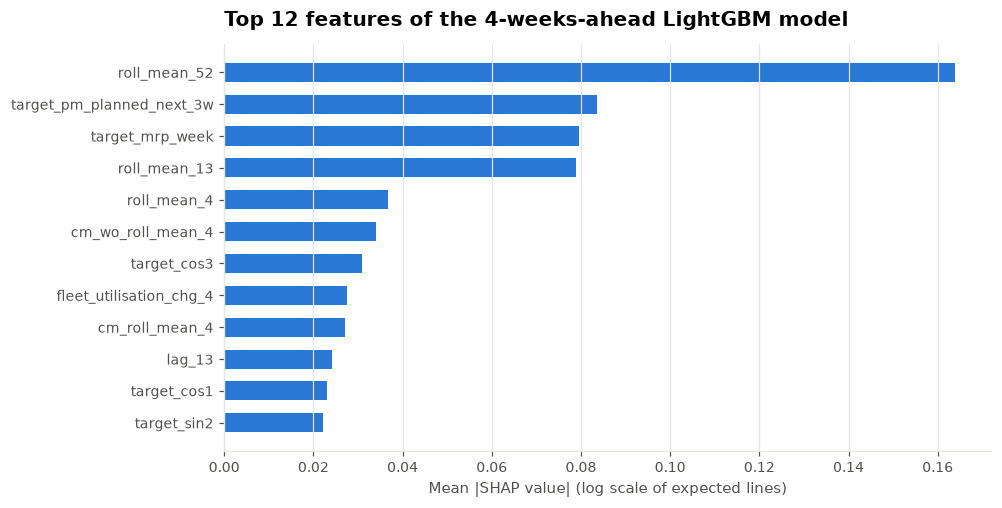

In [5]:
import shap
from p2p.config import TRAIN_END
h = 4
cutoff = pd.Timestamp(TRAIN_END)
_, model = mm.fit_predict_horizon("LightGBM", h, cutoff)
dm = mm.design_matrix(h)
X_explain = dm[(dm.origin_week > cutoff - pd.Timedelta(weeks=52 + h)) & (dm.origin_week <= cutoff - pd.Timedelta(weeks=h))][mm.FEATURES]
explainer = shap.TreeExplainer(model)
sv = explainer(X_explain)

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=mm.FEATURES).sort_values(ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(imp.index, imp.values, color=SERIES[0], height=0.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean |SHAP value| (log scale of expected lines)")
ax.set_title("Top 12 features of the 4-weeks-ahead LightGBM model")
plt.show()

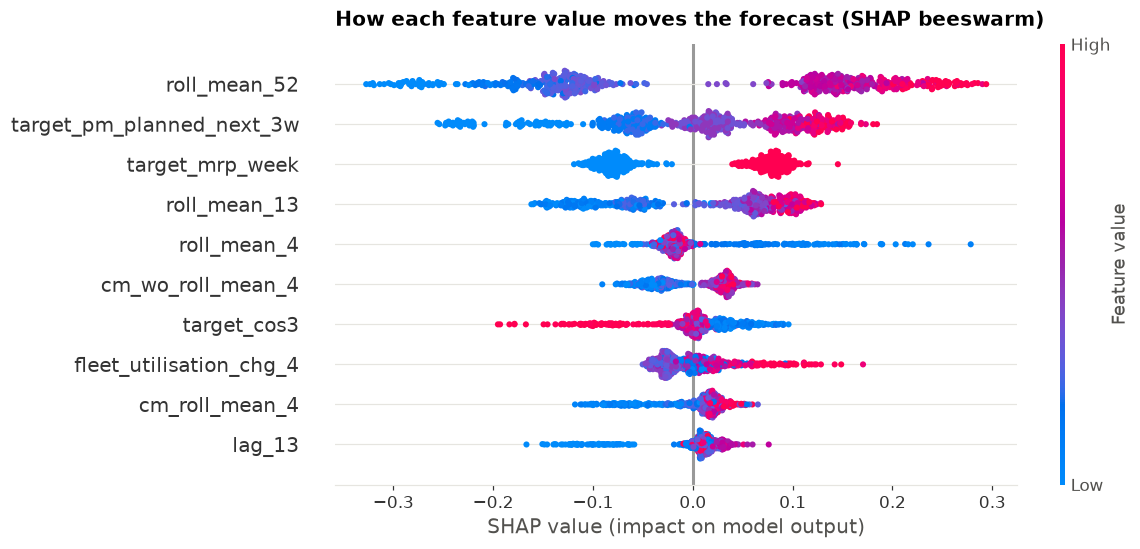

In [6]:
plt.figure()
shap.plots.beeswarm(sv[:, imp.index[::-1][:10].tolist()], max_display=10, show=False, color_bar=True)
plt.title("How each feature value moves the forecast (SHAP beeswarm)", loc="left", fontsize=13)
plt.gcf().set_size_inches(10, 5.2)
plt.show()

**What we see.**

* **Level features dominate** (the 52-week and 13-week rolling means): the model first learns "how big is this section normally".
  That is what the statistical models do too.
* **The maintenance plan for the target week** is the strongest driver after the level: a high planned-maintenance load (red dots on
  the right) raises the forecast. The model learned the same mechanism SARIMAX expressed as a coefficient.
* **The MRP restock week** splits cleanly into two groups: MRP weeks (red) push the forecast up, other weeks pull it down.
* **Recent corrective activity** (breakdowns in the last 4 weeks) and rising fleet utilisation push the next month up.

These are the real drivers built into the simulator (notebook 01). **The model found the true causes, not spurious correlations**,
which is the best possible validation of an explanation method and only possible because we know the ground truth.

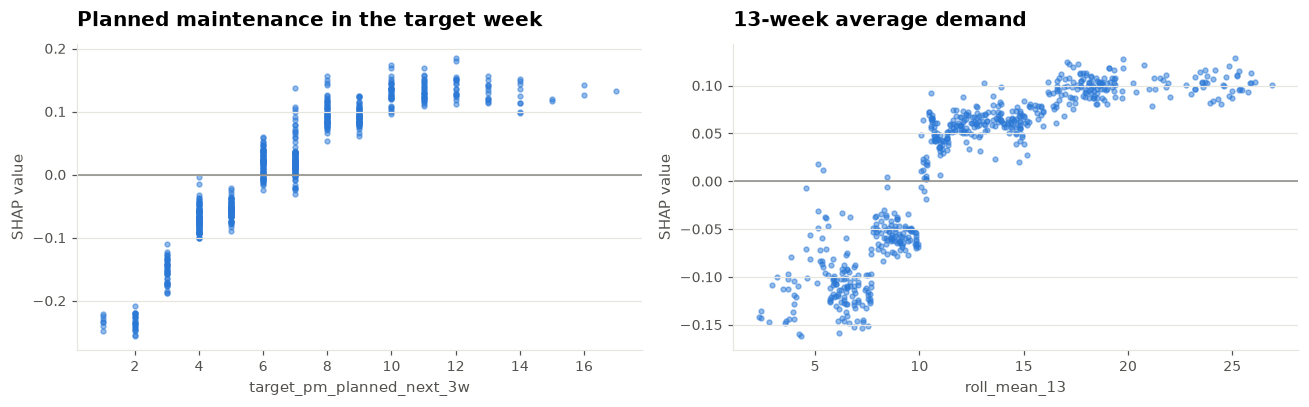

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, feat in zip(axes, ["target_pm_planned_next_3w", "roll_mean_13"]):
    i = mm.FEATURES.index(feat)
    ax.scatter(X_explain[feat], sv.values[:, i], s=10, alpha=0.5, color=SERIES[0])
    ax.axhline(0, color=BRAND["muted"], lw=1)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP value")
axes[0].set_title("Planned maintenance in the target week"); axes[1].set_title("13-week average demand")
plt.tight_layout(); plt.show()

**What we see.** Both relationships rise and then flatten: more planned maintenance means more requisitions until about 10 planned work
orders, after which extra work orders add little (they reuse parts already requested). A higher recent level means a higher forecast,
with diminishing effect for the largest sections. A planner can read these charts without any statistics background.

## 5. Explaining one forecast to a manager

In [8]:
row = X_explain[X_explain.section_code == 11].iloc[[-1]]           # Engine Room, latest week explained
sv_row = explainer(row)
contrib = pd.Series(sv_row.values[0], index=mm.FEATURES)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6)
base = float(np.exp(sv_row.base_values[0])); pred = float(model.predict(row)[0])
print(f"Engine Room, 4 weeks ahead: average forecast {base:.1f} lines -> this forecast {pred:.1f} lines")
for f, v in top.items():
    print(f"  {f:28s} value {row[f].iloc[0]:8.2f}   effect {'+' if v >= 0 else ''}{(np.exp(v) - 1):.0%}")

Engine Room, 4 weeks ahead: average forecast 10.6 lines -> this forecast 13.8 lines
  fleet_utilisation            value     0.81   effect +14%
  target_mrp_week              value     1.00   effect +12%
  target_cos1                  value     0.99   effect -8%
  roll_mean_52                 value     7.08   effect -6%
  cm_wo_roll_mean_4            value     4.25   effect +5%
  target_cos3                  value     0.94   effect -5%


This is the format the AI agent uses when a manager asks "why is next month's forecast high for Engine Room?": the baseline, the
forecast and the three to six drivers that moved it, in percent.

## 6. Where are the errors?

In [9]:
both = pd.concat([ml_val[ml_val.model == "LightGBM"], stats_val[stats_val.model == "SARIMAX (Fourier + PM plan)"]])
by_sec = both.assign(ae=lambda d: (d.y - d.yhat).abs() / d.unique_id.map(scale)).groupby(["unique_id", "model"]).ae.mean().unstack()
from p2p.data import weekly_section
names = weekly_section().drop_duplicates("section_id").set_index("section_id").section_name
by_sec.index = by_sec.index.map(names)
by_sec["LightGBM gain"] = 1 - by_sec["LightGBM"] / by_sec["SARIMAX (Fourier + PM plan)"]
display(by_sec.sort_values("LightGBM gain", ascending=False).round(3))

model,LightGBM,SARIMAX (Fourier + PM plan),LightGBM gain
unique_id,,,
Deck and Safety,0.770,0.862,0.107
Reach Stackers,0.743,0.784,0.053
Cranes and Lifting,0.663,0.696,0.047
Port Infrastructure,0.816,0.853,0.044
Engine Room,0.548,0.569,0.037
Heavy Duty Trucks,0.859,0.878,0.022
Tugboats,0.862,0.878,0.018
Low Voltage Electrical,0.737,0.742,0.006
Minor Equipment,0.586,0.587,0.002


**What we see.** LightGBM beats SARIMAX in 9 of 12 sections. Its largest gains are in the erratic sections (Deck and Safety +11%, Reach
Stackers +5%), where learning across sections helps to separate project spikes from the normal level. SARIMAX stays better in Light
Vehicles, the largest and smoothest section, where a well-specified single-series model has enough data of its own.

## 7. Summary

| Finding | Evidence |
|---|---|
| Global gradient boosting is the most accurate family so far | Validation MASE 0.750 vs 0.765 (SARIMAX) |
| Poisson loss is the right choice for counts | Tuning: config A beats squared error |
| Conformal intervals are well calibrated | 80% coverage close to 0.80 |
| The model learned the true demand drivers | SHAP ranks level, maintenance plan, calendar and breakdowns, the drivers planted in the simulator |
| Every forecast can be explained in business terms | Per-forecast SHAP breakdown |

**Next:** notebook 09 tests deep learning and a pretrained foundation model.